# Drone RL — independent PPO, DQN, and SAC results

To view a saved result, run **Setup**, **Load the RNN**, **Choose a mission**,
and **Plot helpers**, then
run only the desired enabled algorithm's **Results** cell. No training cell or other
algorithm's results cell is required. Checkpoint paths are editable in Setup.
Set `SKIP_DQN` / `SKIP_SAC` in Setup; both default to `True` and skip training
and results, so Run All runs PPO only. Choose the mission before creating environments.

Each algorithm has an optional training cell, its own flight plot,
and its own learning curve. Physical state stays `[z, vz, az]`; the policy observes
`[z-z_ref, vz, az]`. Training, evaluation, plots, and exports use the selected mission.


## Setup


In [1]:
# Run once if needed, then restart the kernel:
# %pip install gymnasium stable-baselines3 numpy matplotlib scipy

import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import gymnasium as gym
from stable_baselines3 import PPO, DQN, SAC
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.results_plotter import load_results

PROJECT_ROOT = next(
    (candidate for directory in (Path.cwd(), *Path.cwd().parents)
     for candidate in (directory, directory / "EI-DATA-DRIVEN-CONTROL")
     if (candidate / "rnn_model/rnn_training.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run from the drone project or rl_interface/ to find rnn_model/rnn_training.py")
sys.path.insert(0, str(PROJECT_ROOT / "rl_interface"))
# Choose "z_angles" for rotation, or "z" for the previous altitude model.
RNN_VARIANT = "z_angles"
if RNN_VARIANT == "z_angles":
    from lib.droneEnvRotation import DroneEnv, PARAMS, Z_LAND, default_mission, run_episode, evaluate
elif RNN_VARIANT == "z":
    from lib.droneEnv import DroneEnv, PARAMS, Z_LAND, default_mission, run_episode, evaluate
else:
    raise ValueError("RNN_VARIANT must be 'z_angles' or 'z'")
from lib.rnn_loader import load_rnn_model

from stable_baselines3.common.callbacks import EvalCallback, StopTrainingOnRewardThreshold

SEED = 0
# Skip both training and results for these algorithms during Run All.
SKIP_DQN = True
SKIP_SAC = True
torch.set_num_threads(1)
# Saved results: edit one path to inspect a different checkpoint.
MODEL_PATH = PROJECT_ROOT / "rl_model" / ("ppo_drone_z_angles.zip" if RNN_VARIANT == "z_angles" else "ppo_drone_rnn.zip")
PPO_MODEL_PATH = MODEL_PATH if RNN_VARIANT == "z_angles" else PROJECT_ROOT / 'rl_interface/logs/rl_comparison_20261103_155235/ppo/ppo_drone_rnn.zip'
DQN_MODEL_PATH = PROJECT_ROOT / 'rl_interface/logs/tuning_dqn_multistep_20261103_163054/best_model.zip'
SAC_MODEL_PATH = PROJECT_ROOT / 'rl_interface/logs/tuning_sac_smooth_20261103_163155/best_model.zip'

# New training runs get separate folders; plotting does not create or require them.
RUN_DIR = PROJECT_ROOT / "rl_interface" / "logs" / f"rl_{RNN_VARIANT}_tuned_{time.strftime('%Y%m%d_%H%M%S')}"
LOG_DIR = PROJECT_ROOT / "rl_interface" / "export_logs" / RNN_VARIANT
PPO_DIR = RUN_DIR / "ppo"
PPO_STEPS = 500000
PPO_PARAMS = {'learning_rate': 0.0001,
 'n_steps': 256,
 'batch_size': 128,
 'gamma': 0.99,
 'gae_lambda': 0.95,
 'n_epochs': 10,
 'clip_range': 0.2}
# Base exploration remains broader; yaw differential is highly sensitive.
PPO_INITIAL_LOG_STD = (-1.5, -3.0) if RNN_VARIANT == "z_angles" else None
DQN_DIR = RUN_DIR / "dqn"
DQN_STEPS = 500000
DQN_PARAMS = {'learning_rate': 0.0001,
 'buffer_size': 100000,
 'learning_starts': 1000,
 'batch_size': 128,
 'train_freq': 5,
 'gradient_steps': -1,
 'n_steps': 3,
 'target_update_interval': 1000,
 'tau': 0.1,
 'exploration_fraction': 1.0,
 'policy_kwargs': {'net_arch': [64, 64]}}
SAC_DIR = RUN_DIR / "sac"
SAC_STEPS = 500000
SAC_PARAMS = {'learning_rate': 0.0003,
 'buffer_size': 100000,
 'learning_starts': 1000,
 'batch_size': 128,
 'train_freq': 1,
 'gradient_steps': -1,
 'ent_coef': 'auto_0.05',
 'use_sde': True,
 'sde_sample_freq': 4,
 'use_sde_at_warmup': True,
 'policy_kwargs': {'net_arch': [64, 64], 'log_std_init': -2}}
SAC_ACTION_LIMIT = 0.8


## Load the trained RNN and head

`RNN_VARIANT="z_angles"` selects `rnn_model/rnn_model_z_and_angles` and the
rotation environment. The checkpoint has a 4-input, 32-hidden-unit, one-layer
RNN and a 32 → 64 → 4 head with Tanh between its linear layers.

Set `RNN_VARIANT="z"` to select the previous altitude environment and
`rnn_model/rnn_model_robust`, whose head is a single linear layer.
The original model and training files are retained.

The loader reads dimensions from the weights and loads them strictly, without
running either training script. Extracted checkpoint files are repacked in
memory. Each environment keeps its own recurrent hidden state.


In [2]:
model_path = PROJECT_ROOT / "rnn_model" / (
    "rnn_model_z_and_angles" if RNN_VARIANT == "z_angles" else "rnn_model_robust"
)
acceleration_rnn = load_rnn_model(model_path, head_activation="tanh")

print("Model:", model_path)
print("Load: all checkpoint weights matched")
print("RNN:", acceleration_rnn.rnn)
print("Head:", acceleration_rnn.head)


Model: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/rnn_model/rnn_model_z_and_angles
Load: all checkpoint weights matched
RNN: RNN(4, 32, batch_first=True)
Head: Sequential(
  (0): Linear(in_features=32, out_features=64, bias=True)
  (1): Tanh()
  (2): Linear(in_features=64, out_features=4, bias=True)
)


## Choose a mission

Edit `ref_mission(t)` below. All environments use it for training, evaluation,
and export. Rerun this cell and recreate environments after editing it.

The environment supplies only `ref_mission(t)` at the current time. The policy
receives `[z - z_ref(t), vz, az]`; the mission function and future targets are
not policy inputs. Full reference curves are used only for plots and reference
generation during MATLAB replay.


In [3]:
def ref_mission(t):
    """Return (z_ref, theta_ref, phi_ref, psi_ref), keeping roll/pitch at zero."""
    if RNN_VARIANT == "z":
        return 0.0 if t < 2.0 else (2.0 if t < 6.0 else Z_LAND)
    if t < 2.0:
        return (0.0, 0.0, 0.0, 0.0)                 # Step 1: On the platform (z = 0)
    elif t < 5.0:
        return (1.0, 0.0, 0.0, 0.0)                 # Step 2: Climb and hold altitude (z = 1.0)
    elif t < 8.0:
        return (1.0, 0.0, 0.0, float(2.0 * np.pi * (t - 5.0) / 3.0))  # Step 3: Hold altitude and complete 360° yaw turn
    else:
        return (Z_LAND, 0.0, 0.0, float(2.0 * np.pi))



## Plot helpers

Shared action wrappers and plotting functions; this cell does not train or load a policy.


In [4]:
DQN_COMMANDS = np.linspace(-3.0, 3.0, 61, dtype=np.float32)

class DiscreteDroneActions(gym.ActionWrapper):
    def __init__(self, env):
        super().__init__(env)
        self.action_space = gym.spaces.Discrete(len(DQN_COMMANDS))

    def action(self, index):
        return np.array([DQN_COMMANDS[int(index)]], dtype=np.float32)

class LimitedCommands(gym.Wrapper):
    def __init__(self, env, limit):
        super().__init__(env)
        self.action_space = gym.spaces.Box(-limit, limit, env.action_space.shape, dtype=np.float32)

def show_result(name, checkpoint, mission_to_test = None):
    checkpoint = Path(checkpoint)
    load_kwargs = {"replay_buffer_class": None} if name == "DQN" else {}
    model = {"PPO": PPO, "DQN": DQN, "SAC": SAC}[name].load(checkpoint, device="cpu", **load_kwargs)
    commands = np.load(checkpoint.parent / "commands.npy") if name == "DQN" else None

    def learned_policy(obs):
        action = model.predict(obs, deterministic=True)[0]
        return np.array([commands[int(action)]], dtype=np.float32) if commands is not None else action

    if mission_to_test is not None:
        eval_env = DroneEnv(rnn_model=acceleration_rnn, mission=mission_to_test)
    else:
        eval_env = DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission)
    print(f"{name}: {checkpoint} ({model.num_timesteps:,} training steps)")
    states, actions, total, outcome = run_episode(eval_env, learned_policy, seed=100)
    base = eval_env.unwrapped
    mission = base.mission
    t = np.arange(len(states)) * base.p.dt
    u = np.asarray(actions).reshape(len(actions), -1)
    targets = np.asarray([mission(float(ti)) for ti in t])
    z_target = targets if targets.ndim == 1 else targets[:, 0]
    has_psi = states.shape[1] > 11
    mae = np.mean(np.abs(states[1:, 0] - z_target[1:]))
    rms_du = np.sqrt(np.mean(np.diff(np.vstack([np.zeros((1, u.shape[1])), u]), axis=0) ** 2))
    status = ", ".join(outcome) if isinstance(outcome, tuple) else outcome
    print(f"{name}: {status} at {t[-1]:.2f} s | return {total:.1f} | "
          f"MAE {mae:.3f} m | peak altitude {states[:, 0].max():.3f} m | "
          f"final vz {states[-1, 1]:.3f} m/s | RMS delta-u {rms_du:.3f}")
    if has_psi:
        print(f"Final psi: {states[-1, 11]:.3f} rad ({np.degrees(states[-1, 11]):.1f} deg)")
    horizon = base.max_steps * base.p.dt
    duration = t[-1]
    end = min(horizon, duration + 0.25) if duration < 2.0 else horizon
    fig, axes = plt.subplots(6 if has_psi else 3, 1,
                             figsize=(9, 12 if has_psi else 7), sharex=True)
    mask = t <= end
    line, = axes[0].plot(t[mask], states[mask, 0], label=f"{name}: {status} at {t[-1]:.2f} s")
    color = line.get_color()
    axes[1].plot(t[mask], states[mask, 1], color=color)
    final_values = [states[-1, 0], states[-1, 1]]
    ylabels = ["Altitude z (m)", "Velocity vz (m/s)"]
    if has_psi:
        # Physical angles from the environment; yaw keeps complete turns visible.
        angle_specs = [(11, "psi", "Yaw psi (rad)"),
                       (9, "theta", "Pitch theta (rad)"),
                       (10, "phi", "Roll phi (rad)")]
        for ax, (index, angle, ylabel) in zip(axes[2:5], angle_specs):
            ax.plot(t[mask], states[mask, index], color=color, label=f"Environment {angle}")
            final_values.append(states[-1, index])
            ylabels.append(ylabel)
    padded_u = np.vstack([u, u[-1:]])
    command_labels = ["u_base", "u_diff"] if u.shape[1] == 2 else [f"u{i + 1}" for i in range(u.shape[1])]
    for channel, label in enumerate(command_labels):
        command_line, = axes[-1].step(t[mask], padded_u[mask, channel],
                                      where="post", label=label)
        if t[-1] <= end:
            axes[-1].plot(t[-1], u[-1, channel], "x", color=command_line.get_color())
    if u.shape[1] > 1:
        axes[-1].legend(fontsize=8)
    if t[-1] <= end:
        for ax, value in zip(axes[:-1], final_values):
            ax.plot(t[-1], value, "x", color=color)
        for ax in axes:
            ax.axvline(t[-1], color=color, linestyle=":", alpha=0.4)
    reference_t = np.arange(0, end + base.p.dt / 2, base.p.dt)
    reference = np.asarray([mission(float(ti)) for ti in reference_t])
    z_reference = reference if reference.ndim == 1 else reference[:, 0]
    axes[0].step(reference_t, z_reference, where="post",
                 color="black", linestyle="--", label="Mission target")
    if has_psi:
        # Four-reference rotation missions use (z, theta, phi, psi).
        # Older (z, psi) missions imply level roll/pitch targets.
        theta_reference = np.zeros_like(reference_t)
        phi_reference = np.zeros_like(reference_t)
        psi_reference = np.zeros_like(reference_t)
        if reference.ndim == 2:
            psi_reference = reference[:, -1]
            if reference.shape[1] == 4:
                theta_reference = reference[:, 1]
                phi_reference = reference[:, 2]
        for ax, target, angle in zip(axes[2:5],
                                     [psi_reference, theta_reference, phi_reference],
                                     ["psi", "theta", "phi"]):
            ax.plot(reference_t, target, color="black", linestyle="--",
                    label=f"Mission {angle} target")
            ax.legend(fontsize=8)
    ylabels.append("Command u")
    for ax, ylabel in zip(axes, ylabels):
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
    axes[0].set_title(f"{name} — saved policy")
    axes[0].legend(fontsize=8)
    axes[-1].set(xlabel="Time (s)", xlim=(0, end))
    fig.tight_layout()
    plt.show()
    eval_env.close()

    if list(checkpoint.parent.glob("*.monitor.csv")):
        history = load_results(str(checkpoint.parent))
        returns = history["r"].to_numpy()
        steps = history["l"].cumsum().to_numpy()
        window = min(20, len(returns))
        fig, ax = plt.subplots(figsize=(9, 3))
        if window:
            ax.plot(steps[window - 1:], np.convolve(returns, np.ones(window) / window, "valid"),
                    label=f"Training: mean over {window} episodes", alpha=0.7)
        evaluation_file = checkpoint.parent / "evaluations.npz"
        if evaluation_file.is_file():
            with np.load(evaluation_file) as evaluations:
                ax.plot(evaluations["timesteps"], evaluations["results"].mean(axis=1),
                        marker=".", label="Deterministic evaluation")
        ax.axvline(model.num_timesteps, color="black", linestyle=":", label="Loaded checkpoint")
        ax.set(title=f"{name} learning curve", xlabel="Environment steps", ylabel="Episode return")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
        fig.tight_layout()
        plt.show()

## Optional environment check


In [5]:
env = DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission)
check_env(env)
obs, info = env.reset(seed=SEED)
print("Observation:", obs, env.observation_space)
print("Action:", env.action_space)
print("check_env: OK")
env.close()


Observation: [ 0.     0.    -9.816  0.     0.     0.     0.     0.     0.     0.
  0.     0.   ] Box([ -10.         -20.        -100.          -3.1415927   -3.1415927
   -6.2831855  -50.        -500.         -50.        -500.
  -50.        -500.       ], [ 10.         20.        100.          3.1415927   3.1415927   6.2831855
  50.        500.         50.        500.         50.        500.       ], (12,), float32)
Action: Box(-3.0, 3.0, (2,), float32)
check_env: OK


/home/rayan768/venvs/main_env/lib/python3.13/site-packages/stable_baselines3/common/env_checker.py:515: UserWarning: We recommend you to use a symmetric and normalized Box action space (range=[-1, 1]) cf. https://stable-baselines3.readthedocs.io/en/master/guide/rl_tips.html
  warnings.warn(


## PPO — optional training

Keep the recipe that already lands: learning rate `1e-4`, `n_steps=256`, batch
size `128`, gamma `0.99`, and 10 epochs. With 10 environments, a rollout contains
2560 transitions. The low learning rate and clipped updates preserve the working
baseline. These exact values are supported by this local run, not prescribed for
this drone by a paper. [PPO parameter documentation](https://stable-baselines3.readthedocs.io/en/master/modules/ppo.html#parameters).


In [6]:
ppo_env = make_vec_env(
    lambda: DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission),
    n_envs=10, seed=SEED, monitor_dir=str(PPO_DIR),
)
agent = PPO("MlpPolicy", ppo_env, seed=SEED, device="cpu", verbose=0, **PPO_PARAMS)
if PPO_INITIAL_LOG_STD is not None:
    with torch.no_grad():
        agent.policy.log_std.copy_(torch.tensor(PPO_INITIAL_LOG_STD, dtype=torch.float32))

ppo_eval_env = make_vec_env(
    lambda: DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission),
    n_envs=1, seed=100,
)
ppo_callback = EvalCallback(
    ppo_eval_env, best_model_save_path=str(PPO_DIR), log_path=str(PPO_DIR),
    eval_freq=max(1, 20480 // ppo_env.num_envs), n_eval_episodes=1,
    deterministic=True, verbose=0,
)
start = time.perf_counter()
agent.learn(total_timesteps=PPO_STEPS, callback=ppo_callback)
trained_steps = agent.num_timesteps
final_model_path = PPO_DIR / "ppo_drone_rnn.zip"
agent.save(final_model_path)
PPO_MODEL_PATH = PPO_DIR / "best_model.zip"
if not PPO_MODEL_PATH.is_file():
    PPO_MODEL_PATH = final_model_path
# Results and the export cell use the same evaluated checkpoint.
agent = PPO.load(PPO_MODEL_PATH, device="cpu")
ppo_env.close()
ppo_eval_env.close()
print(f"PPO: {trained_steps:,} steps in {time.perf_counter() - start:.1f} s; {PPO_MODEL_PATH}")


PPO: 501,760 steps in 219.7 s; /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/rl_interface/logs/rl_z_angles_tuned_20261104_180358/ppo/ppo_drone_rnn.zip


## PPO — Results

Run this cell directly after the shared setup cells to load the saved PPO.


PPO: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/rl_interface/logs/rl_z_angles_tuned_20261104_180358/ppo/ppo_drone_rnn.zip (501,760 training steps)
PPO: crashed, no_turn at 3.05 s | return -2101.5 | MAE 0.572 m | peak altitude 0.646 m | final vz -1.455 m/s | RMS delta-u 0.949
Final psi: -1.388 rad (-79.5 deg)


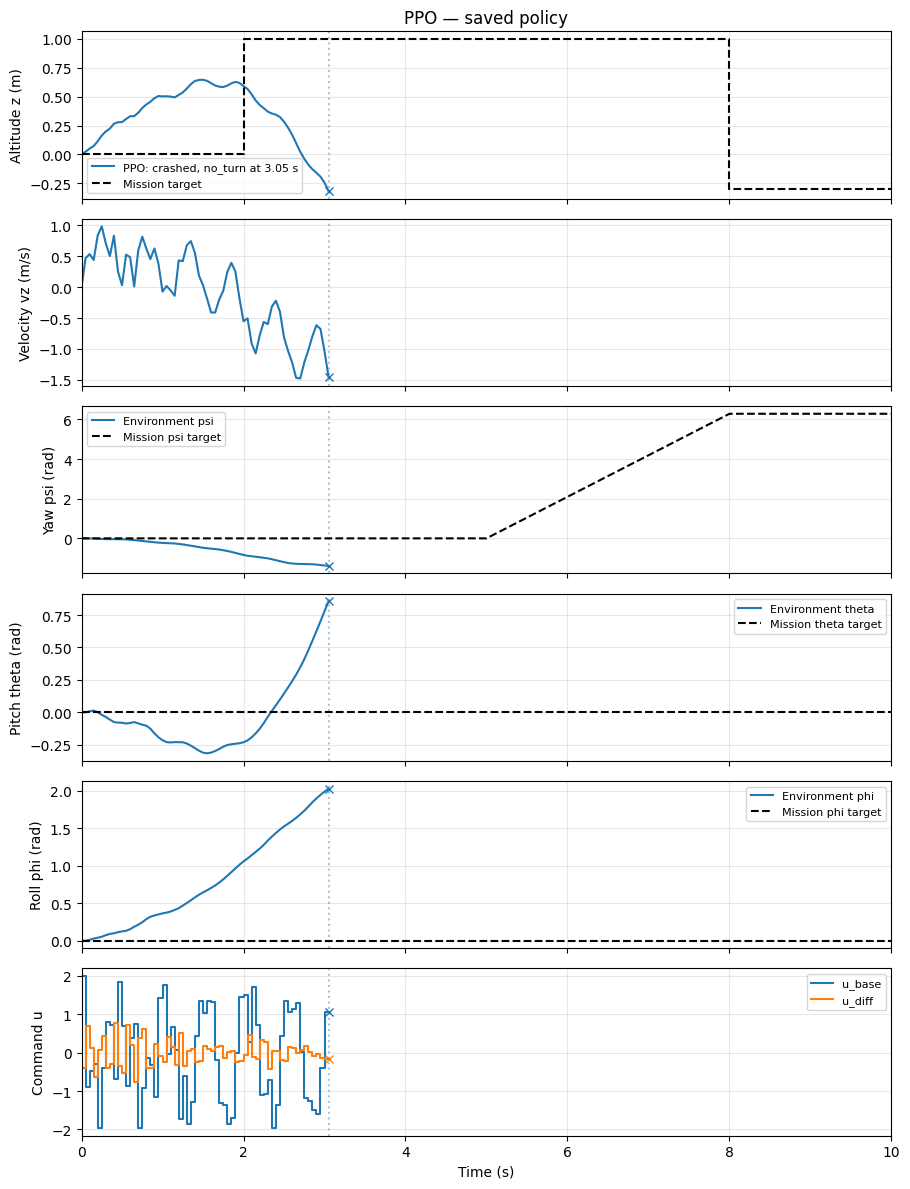

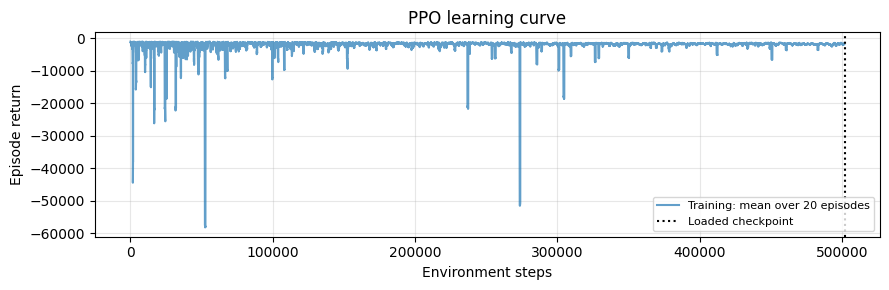

In [7]:
show_result("PPO", PPO_MODEL_PATH)


In [8]:
agent.save(MODEL_PATH)
print("Saved:", MODEL_PATH.with_suffix(".zip"))

# The existing MATLAB exporter handles the previous single-command model.
EXPORT_MATLAB = RNN_VARIANT == "z"
if EXPORT_MATLAB:
    from export_policy import export_for_matlab
    export_env = DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission)
    export_for_matlab(agent, export_env)
    from scipy.io import loadmat, savemat
    exported_policy = {k: v for k, v in loadmat("policy.mat").items() if not k.startswith("__")}
    mission_t = np.arange(export_env.max_steps + 1) * export_env.p.dt
    exported_policy["mission_t"] = mission_t.reshape(-1, 1)
    exported_policy["mission_z_ref"] = np.array([export_env.mission(float(t)) for t in mission_t]).reshape(-1, 1)
    savemat("policy.mat", exported_policy)
    export_env.close()

Saved: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/rl_model/ppo_drone_z_angles.zip


## Changing mission

In [9]:
def test_mission(t):
    """Return (z_ref, theta_ref, phi_ref, psi_ref), keeping roll/pitch at zero."""
    if RNN_VARIANT == "z":
        return 0.0 if t < 2.0 else (2.0 if t < 5.0 else Z_LAND)
    if t < 2.0:
        return (0.0, 0.0, 0.0, 0.0)                 # Step 1: On the platform (z = 0)
    elif t < 5.0:
        return (2.0, 0.0, 0.0, 0.0)                 # Step 2: Climb and hold altitude (z = 1.0)
    elif t < 8.0:
        return (2.0, 0.0, 0.0, float(2.0 * np.pi * (t - 5.0) / 3.0))  # Step 3: Hold altitude and complete 360° yaw turn
    else:
        return (Z_LAND, 0.0, 0.0, float(2.0 * np.pi))  

PPO: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/rl_interface/logs/rl_z_angles_tuned_20261104_180358/ppo/ppo_drone_rnn.zip (501,760 training steps)
PPO: crashed, no_turn at 3.15 s | return -2620.4 | MAE 0.955 m | peak altitude 0.646 m | final vz -1.720 m/s | RMS delta-u 0.918
Final psi: -1.376 rad (-78.8 deg)


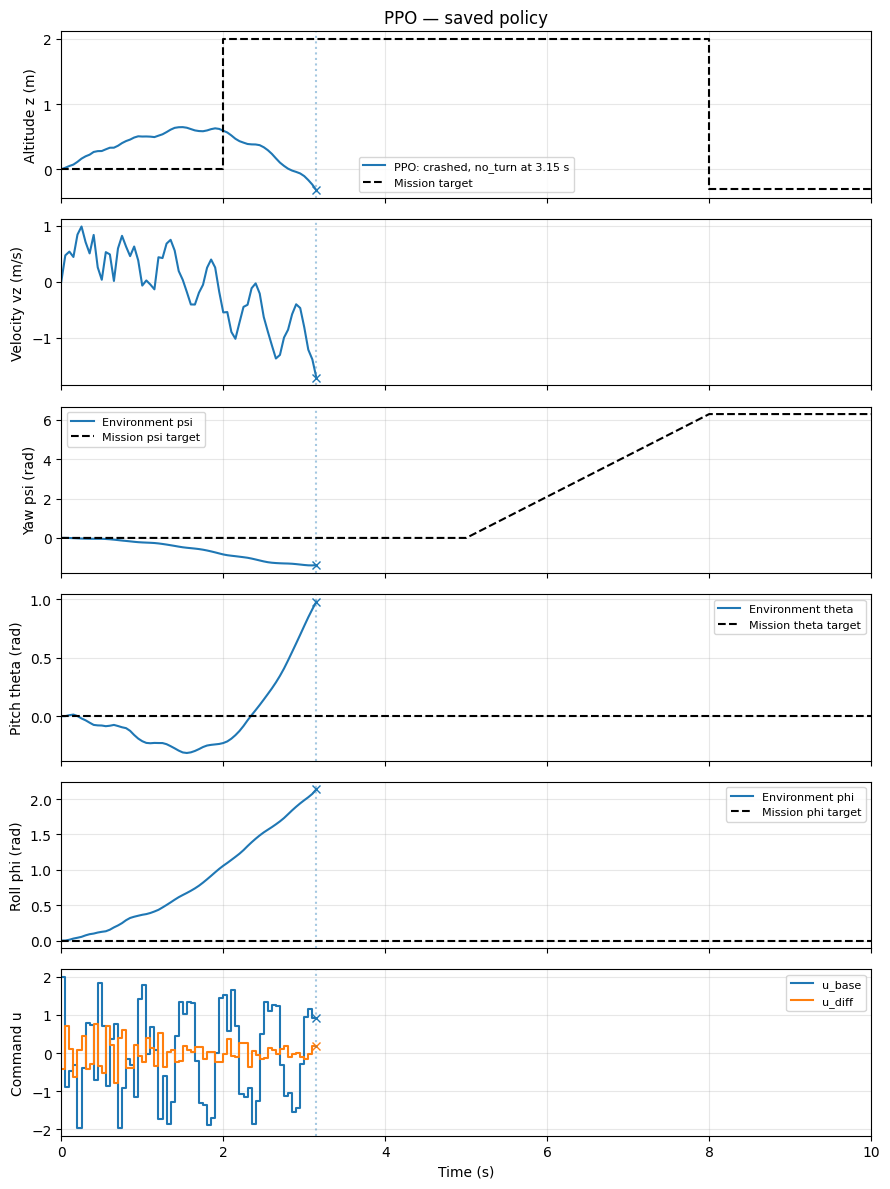

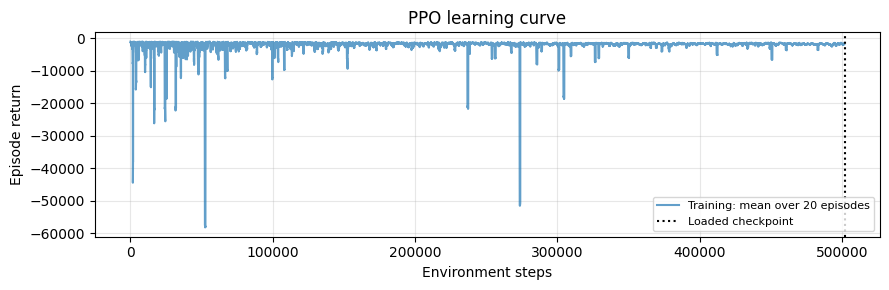

In [10]:
show_result("PPO", PPO_MODEL_PATH, mission_to_test=test_mission)

## DQN — optional training

Skipped when `SKIP_DQN=True` in Setup.

Use 61 commands evenly spaced across `[-3.0, 3.0]` (0.1 increments), covering
its full environment action range for the selected mission. Rerun this training
cell to learn with the wider command range; existing checkpoints retain their
original saved `commands.npy`. The Results cell reports peak altitude so you can
check whether the trained policy reaches its target.

Use learning rate `1e-4`, batch `128`, `train_freq=5`, and `gradient_steps=-1`:
with 10 environments, 50 collected transitions are followed by 50 updates.
`n_steps=3` passes rewards across three transitions; `tau=0.1` and
`target_update_interval=1000` smooth the target updates.
`exploration_fraction=1.0` decays epsilon throughout the training run.
These choices target sparse landing rewards and the observed training regressions.

Sources: [DQN parameters](https://stable-baselines3.readthedocs.io/en/master/modules/dqn.html#parameters),
[multi-environment update guidance](https://stable-baselines3.readthedocs.io/en/master/guide/examples.html#multiprocessing-with-off-policy-algorithms).


In [11]:
if SKIP_DQN:
    print("DQN skipped (SKIP_DQN=True).")
else:
    def make_dqn_env():
        env = DiscreteDroneActions(DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission))
        return env

    dqn_env = make_vec_env(make_dqn_env, n_envs=10, seed=SEED, monitor_dir=str(DQN_DIR))
    dqn_eval = make_vec_env(make_dqn_env, n_envs=1, seed=100)
    dqn_callback = EvalCallback(
        dqn_eval, best_model_save_path=str(DQN_DIR), log_path=str(DQN_DIR),
        eval_freq=500, n_eval_episodes=1, deterministic=True, verbose=0,
        callback_on_new_best=StopTrainingOnRewardThreshold(reward_threshold=0.0, verbose=1),
    )
    dqn_agent = DQN("MlpPolicy", dqn_env, seed=SEED, device="cpu", verbose=0, **DQN_PARAMS)
    start = time.perf_counter()
    dqn_agent.learn(total_timesteps=DQN_STEPS, callback=dqn_callback)
    dqn_agent.save(DQN_DIR / "dqn_drone_rnn")
    np.save(DQN_DIR / "commands.npy", DQN_COMMANDS)
    DQN_MODEL_PATH = DQN_DIR / "best_model.zip"
    dqn_env.close()
    dqn_eval.close()
    print(f"DQN: {dqn_agent.num_timesteps:,} steps in {time.perf_counter() - start:.1f} s; {DQN_MODEL_PATH}")


DQN skipped (SKIP_DQN=True).


## DQN — Results

Skipped when `SKIP_DQN=True` in Setup.

Loads only DQN and its saved `commands.npy`; PPO and SAC do not need to run.


In [12]:
if SKIP_DQN:
    print("DQN skipped (SKIP_DQN=True).")
else:
    show_result("DQN", DQN_MODEL_PATH)


DQN skipped (SKIP_DQN=True).


## SAC — optional training

Skipped when `SKIP_SAC=True` in Setup.

Use learning rate `3e-4`, batch `128`, and `gradient_steps=-1` to match updates
to collected transitions. Explore with `use_sde=True`, `sde_sample_freq=4`,
and `log_std_init=-2`: noise is resampled every 0.2 s instead of independently
at each 0.05 s action. Start entropy tuning at `auto_0.05` to reduce its initial
weight relative to the reward. The notebook wrapper advertises commands in
`[-0.8, 0.8]`; physical command units and library dynamics stay unchanged.

The best 30k-step checkpoint landed at 7.20 s. Later training regressed, so the
Results cell loads that best checkpoint, not the final 50k-step policy.
These values were tested together; their individual effects are unproven.
Sources: [SAC parameters](https://stable-baselines3.readthedocs.io/en/master/modules/sac.html#parameters),
[Smooth Exploration for Robotic Reinforcement Learning](https://arxiv.org/abs/2005.05719),
[RL Zoo SAC configurations](https://github.com/DLR-RM/rl-baselines3-zoo/blob/master/hyperparams/sac.yml).
The sources support the approach; they do not prescribe these exact values for this drone.


In [13]:
if SKIP_SAC:
    print("SAC skipped (SKIP_SAC=True).")
else:
    def make_sac_env():
        env = DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission)
        if SAC_ACTION_LIMIT is not None:
            env = LimitedCommands(env, SAC_ACTION_LIMIT)
        return env

    sac_env = make_vec_env(make_sac_env, n_envs=10, seed=SEED, monitor_dir=str(SAC_DIR))
    sac_eval = make_vec_env(make_sac_env, n_envs=1, seed=100)
    sac_callback = EvalCallback(
        sac_eval, best_model_save_path=str(SAC_DIR), log_path=str(SAC_DIR),
        eval_freq=500, n_eval_episodes=1, deterministic=True, verbose=0,
        callback_on_new_best=StopTrainingOnRewardThreshold(reward_threshold=0.0, verbose=1),
    )
    sac_agent = SAC("MlpPolicy", sac_env, seed=SEED, device="cpu", verbose=0, **SAC_PARAMS)
    start = time.perf_counter()
    sac_agent.learn(total_timesteps=SAC_STEPS, callback=sac_callback)
    sac_agent.save(SAC_DIR / "sac_drone_rnn")
    SAC_MODEL_PATH = SAC_DIR / "best_model.zip"
    sac_env.close()
    sac_eval.close()
    print(f"SAC: {sac_agent.num_timesteps:,} steps in {time.perf_counter() - start:.1f} s; {SAC_MODEL_PATH}")


SAC skipped (SKIP_SAC=True).


## SAC — Results

Skipped when `SKIP_SAC=True` in Setup.

Loads only SAC; PPO and DQN do not need to run.


In [14]:
if SKIP_SAC:
    print("SAC skipped (SKIP_SAC=True).")
else:
    show_result("SAC", SAC_MODEL_PATH)


SAC skipped (SKIP_SAC=True).


## Export a PPO trajectory

Exports `trajectory_az.csv` into this run's PPO directory using the same selected
mission. MATLAB policy export above also includes that mission's reference samples.


In [15]:

# 1. Déroulement d'un épisode avec la politique entraînée
eval_env = DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission)
obs, info = eval_env.reset(seed=0)

az_list = [float(eval_env.unwrapped.state[2])]

terminated = False
truncated = False

while not (terminated or truncated):
    action, _ = agent.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = eval_env.step(action)
    az_list.append(float(eval_env.unwrapped.state[2]))

eval_env.close()

# 2. Export sur une seule ligne (chaque case = une valeur de az)
LOG_DIR.mkdir(parents=True, exist_ok=True)
output_path = LOG_DIR / "trajectory_az.csv"
np.savetxt(output_path, [az_list], delimiter=",", fmt="%.6f")

print(f"Trajectoire az exportée ({len(az_list)} valeurs sur 1 ligne) : {output_path}")

Trajectoire az exportée (62 valeurs sur 1 ligne) : /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/rl_interface/export_logs/z_angles/trajectory_az.csv
